In [14]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
modelo_cnn = tf.keras.models.load_model("model/modelo_cnn.keras")

In [15]:
print("x_test disponible:", "x_test" in globals())

x_test disponible: True


In [16]:
ruta = "data/sign_mnist_test.csv"
datos_test = pd.read_csv(ruta)

# Separar etiquetas y píxeles
label_test = datos_test["label"].to_numpy()
X_test = datos_test.drop(columns="label").to_numpy()

# Normalizar y adaptar dimensiones para la CNN
x_test = (X_test / 255.0).astype("float32")
x_test = x_test.reshape(-1, 28, 28, 1)

print("Dimensiones de x_test:", x_test.shape)
print("Dimensiones de label_test:", label_test.shape)

Dimensiones de x_test: (7172, 28, 28, 1)
Dimensiones de label_test: (7172,)


In [17]:
labels = [i for i in range(25) if i != 9]
mapping = {label: i for i, label in enumerate(labels)}

label_test = np.array([mapping[label] for label in label_test])

In [18]:
print("x_test:", x_test.shape)
print("label_test:", label_test.shape)
print("Clases disponibles:", np.unique(label_test))

x_test: (7172, 28, 28, 1)
label_test: (7172,)
Clases disponibles: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


Dimensiones de los feature maps: (1, 26, 26, 64)


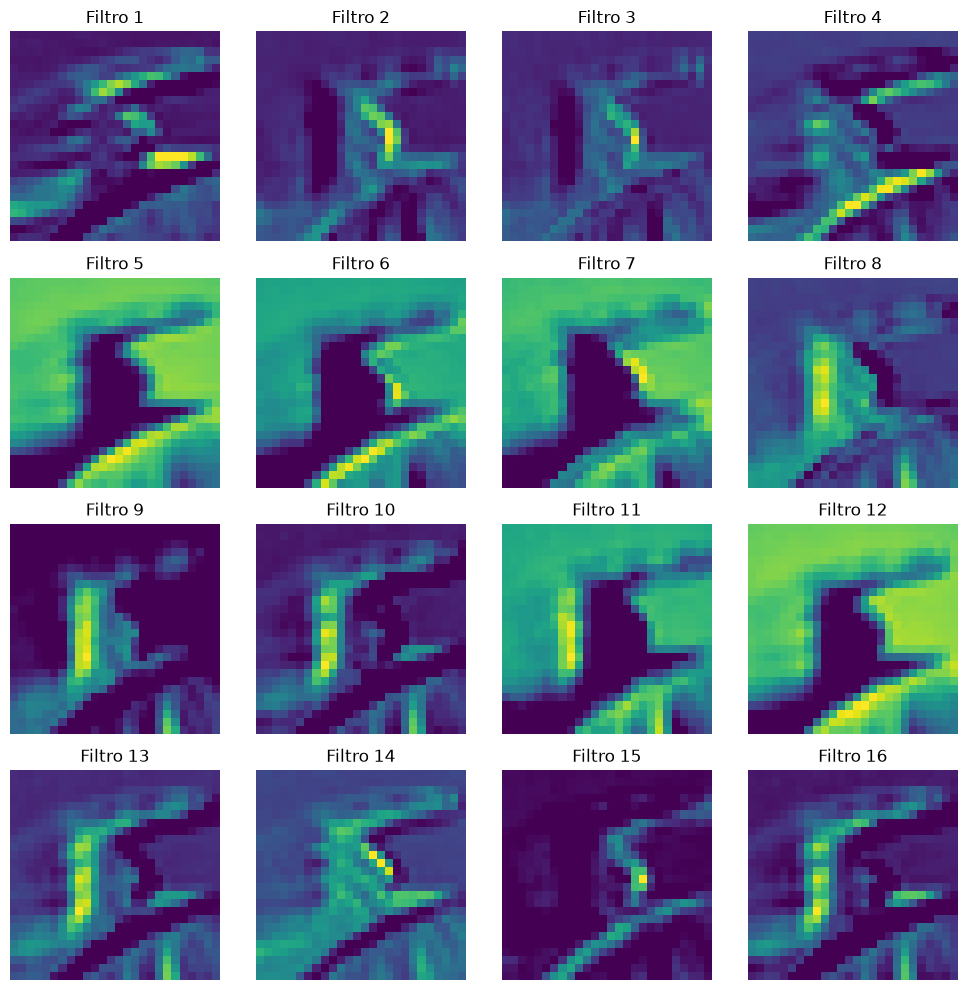

In [19]:
# Seleccionar una imagen
indice = 0
imagen = x_test[indice:indice + 1]

# Extraer las activaciones de la capa convolucional
modelo_features = tf.keras.Model(
    inputs=modelo_cnn.inputs,
    outputs=modelo_cnn.get_layer("conv_1").output
)

feature_maps = modelo_features(imagen, training=False).numpy()

print("Dimensiones de los feature maps:", feature_maps.shape)

# Visualizar los primeros 16 filtros
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Filtro {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()